In [1]:
import pandas as pd

donnees = pd.read_csv(
    "dpe_donnees_communes.csv",
    encoding="utf-8-sig",
    dtype=str
)

cible_regression = "conso_5_usages_ef"

donnees[cible_regression] = pd.to_numeric(
    donnees[cible_regression],
    errors="coerce"
)

df_arbre = donnees.loc[
    donnees[cible_regression].notna()
].copy()

df_train_arbre = df_arbre.loc[
    df_arbre["partition"].eq("train")
].copy()

df_test_arbre = df_arbre.loc[
    df_arbre["partition"].eq("test")
].copy()

print("Train :", len(df_train_arbre))
print("Test :", len(df_test_arbre))

Train : 6914
Test : 3006


In [2]:
variables_numeriques = [
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "surface_climatisee"
]

variables_categorielles = [
    "code_postal_ban",
    "type_batiment",
    "periode_construction",
    "type_energie_principale_chauffage",
    "type_generateur_chauffage_principal",
    "type_installation_chauffage",
    "type_energie_principale_ecs",
    "type_installation_ecs",
    "isolation_toiture",
    "qualite_isolation_menuiseries",
    "type_ventilation",
    "logement_traversant"
]

variables_explicatives = (
    variables_numeriques + variables_categorielles
)

X_train_arbre = df_train_arbre[variables_explicatives].copy()
X_test_arbre = df_test_arbre[variables_explicatives].copy()

y_train_arbre = df_train_arbre[cible_regression].copy()
y_test_arbre = df_test_arbre[cible_regression].copy()

for colonne in variables_numeriques:
    X_train_arbre[colonne] = pd.to_numeric(
        X_train_arbre[colonne],
        errors="coerce"
    )
    X_test_arbre[colonne] = pd.to_numeric(
        X_test_arbre[colonne],
        errors="coerce"
    )

print("X train :", X_train_arbre.shape)
print("X test :", X_test_arbre.shape)

X train : (6914, 15)
X test : (3006, 15)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

preparation_arbre = ColumnTransformer([
    (
        "numerique",
        SimpleImputer(strategy="median"),
        variables_numeriques
    ),
    (
        "categoriel",
        Pipeline([
            (
                "imputation",
                SimpleImputer(
                    strategy="constant",
                    fill_value="Non_renseigne"
                )
            ),
            (
                "encodage",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]),
        variables_categorielles
    )
])

modele_arbre = Pipeline([
    ("preparation", preparation_arbre),
    (
        "modele",
        DecisionTreeRegressor(random_state=42)
    )
])

print("Pipeline de régression créé.")

Pipeline de régression créé.


In [4]:
from sklearn.model_selection import GroupKFold, GridSearchCV

groupes_train_arbre = df_train_arbre.loc[
    X_train_arbre.index,
    "groupe_batiment"
]

validation_arbre = GroupKFold(n_splits=3)

plis_arbre = list(
    validation_arbre.split(
        X_train_arbre,
        y_train_arbre,
        groups=groupes_train_arbre
    )
)

grille_arbre = {
    "modele__max_depth": [3, 5, 10, 20, None],
    "modele__min_samples_leaf": [1, 5, 20]
}

mesures_regression = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

recherche_arbre = GridSearchCV(
    estimator=modele_arbre,
    param_grid=grille_arbre,
    scoring=mesures_regression,
    refit="RMSE",
    cv=plis_arbre,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

recherche_arbre.fit(
    X_train_arbre,
    y_train_arbre
)

print("Meilleurs paramètres :")
print(recherche_arbre.best_params_)

print("\nMeilleur RMSE moyen :")
print(round(-recherche_arbre.best_score_, 3))

resultats_recherche_arbre = pd.DataFrame(
    recherche_arbre.cv_results_
)

tableau_recherche_arbre = pd.DataFrame({
    "max_depth": resultats_recherche_arbre[
        "param_modele__max_depth"
    ],
    "min_samples_leaf": resultats_recherche_arbre[
        "param_modele__min_samples_leaf"
    ],
    "MAE": -resultats_recherche_arbre["mean_test_MAE"],
    "RMSE": -resultats_recherche_arbre["mean_test_RMSE"],
    "R2": resultats_recherche_arbre["mean_test_R2"]
}).sort_values("RMSE")

display(tableau_recherche_arbre.round(3))

modele_arbre_selectionne = recherche_arbre.best_estimator_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Meilleurs paramètres :
{'modele__max_depth': 20, 'modele__min_samples_leaf': 20}

Meilleur RMSE moyen :
5367.686


,max_depth,min_samples_leaf,MAE,RMSE,R2
11,20,20,3033.086,5367.686,0.549
14,None,20,3033.086,5367.686,0.549
8,10,20,3043.077,5371.283,0.548
5,5,20,3418.247,5697.717,0.491
3,5,1,3463.244,5769.137,0.476
6,10,1,3250.999,5904.149,0.448
7,10,5,3271.274,5910.183,0.446
4,5,5,3466.904,5926.741,0.445
10,20,5,3338.857,5980.674,0.433
13,None,5,3340.786,5982.581,0.432


In [5]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred_test_arbre = modele_arbre_selectionne.predict(
    X_test_arbre
)

resultats_test_arbre = pd.DataFrame([{
    "Modèle": "Arbre de régression",
    "RMSE": np.sqrt(
        mean_squared_error(
            y_test_arbre,
            y_pred_test_arbre
        )
    ),
    "MAE": mean_absolute_error(
        y_test_arbre,
        y_pred_test_arbre
    ),
    "R²": r2_score(
        y_test_arbre,
        y_pred_test_arbre
    )
}])

print("Meilleurs paramètres :")
print(recherche_arbre.best_params_)

print("\nRégression — jeu de test")
display(resultats_test_arbre.round(3))

Meilleurs paramètres :
{'modele__max_depth': 20, 'modele__min_samples_leaf': 20}

Régression — jeu de test


,Modèle,RMSE,MAE,R²
0,Arbre de régression,8252.371,2818.669,0.312


In [6]:
predictions_test_arbre = pd.DataFrame({
    "numero_dpe": df_test_arbre.loc[
        X_test_arbre.index,
        "numero_dpe"
    ],
    "consommation_observee": y_test_arbre,
    "consommation_predite": y_pred_test_arbre
})

predictions_test_arbre["erreur"] = (
    predictions_test_arbre["consommation_predite"]
    - predictions_test_arbre["consommation_observee"]
)

display(predictions_test_arbre.head(10).round(2))

print(
    "Nombre de prédictions négatives :",
    int((y_pred_test_arbre < 0).sum())
)

,numero_dpe,consommation_observee,consommation_predite,erreur
8,2669E0050918G,3230.4,4860.04,1629.64
14,2669E0011626A,12840.2,18213.68,5373.47
15,2669E0010326A,7648.2,7842.44,194.24
17,2669E0013614M,7641.8,4993.21,-2648.59
18,2669E0050535N,3244.9,4860.04,1615.14
20,2669E0075265R,8355.0,28820.41,20465.41
24,2669E0062799F,3175.9,3318.62,142.72
27,2669E0029765R,26070.3,41872.90,15802.60
28,2669E0050303P,2604.5,4860.04,2255.54
31,2669E0042689T,4601.8,6615.90,2014.10


Nombre de prédictions négatives : 0


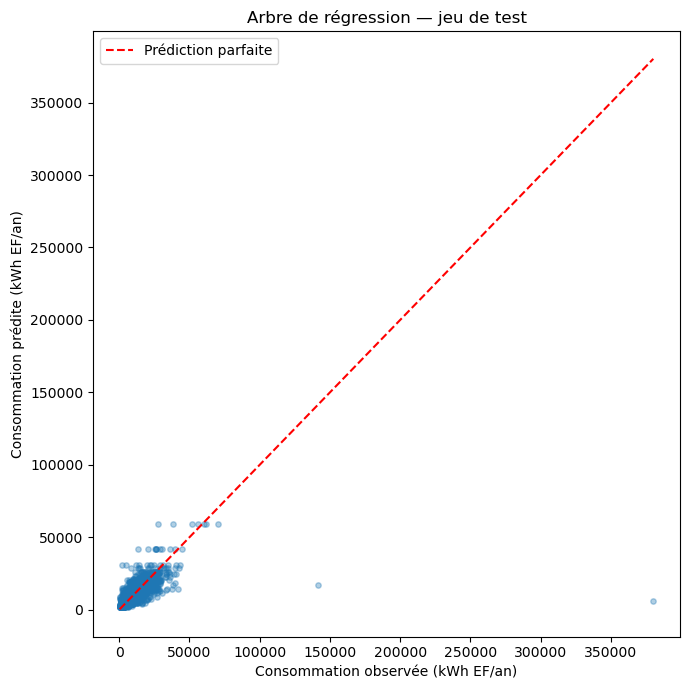

In [7]:
import matplotlib.pyplot as plt

borne_min = min(
    y_test_arbre.min(),
    y_pred_test_arbre.min()
)

borne_max = max(
    y_test_arbre.max(),
    y_pred_test_arbre.max()
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    y_test_arbre,
    y_pred_test_arbre,
    alpha=0.35,
    s=15
)

ax.plot(
    [borne_min, borne_max],
    [borne_min, borne_max],
    color="red",
    linestyle="--",
    label="Prédiction parfaite"
)

ax.set_xlabel("Consommation observée (kWh EF/an)")
ax.set_ylabel("Consommation prédite (kWh EF/an)")
ax.set_title("Arbre de régression — jeu de test")
ax.legend()

fig.tight_layout()
fig.savefig(
    "arbre_observations_predictions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
import joblib

resultats_test_arbre.to_csv(
    "arbre_resultats_finaux.csv",
    index=False,
    encoding="utf-8-sig"
)

predictions_test_arbre.to_csv(
    "arbre_predictions_test.csv",
    index=False,
    encoding="utf-8-sig"
)

tableau_recherche_arbre.to_csv(
    "arbre_recherche_parametres.csv",
    index=False,
    encoding="utf-8-sig"
)

joblib.dump(
    modele_arbre_selectionne,
    "arbre_regression_pipeline.joblib"
)

print("Résultats et modèle enregistrés.")

Résultats et modèle enregistrés.


In [9]:
resultats_ridge = pd.read_csv(
    "ridge_resultats_finaux.csv",
    encoding="utf-8-sig"
).rename(columns={"R2": "R²"})

comparaison_regression_test = pd.concat(
    [
        resultats_ridge[
            ["Modèle", "RMSE", "MAE", "R²"]
        ],
        resultats_test_arbre[
            ["Modèle", "RMSE", "MAE", "R²"]
        ]
    ],
    ignore_index=True
).sort_values("RMSE")

print(
    "=== Régression "
    "(cible : conso_5_usages_ef, en kWh EF/an) ==="
)

display(
    comparaison_regression_test.style
    .format({
        "RMSE": "{:.3f}",
        "MAE": "{:.3f}",
        "R²": "{:.3f}"
    })
    .hide(axis="index")
)

comparaison_regression_test.to_csv(
    "comparaison_regression_test.csv",
    index=False,
    encoding="utf-8-sig"
)

=== Régression (cible : conso_5_usages_ef, en kWh EF/an) ===


Modèle,RMSE,MAE,R²
Ridge,8120.910,3012.212,0.333
Arbre de régression,8252.371,2818.669,0.312


In [ ]:
import pandas as pd
from pathlib import Path

dossier_projet = Path(
    "."
)

classification = pd.read_csv(
    dossier_projet / "classification_resultats_finaux.csv",
    encoding="utf-8-sig"
)

ridge = pd.read_csv(
    dossier_projet / "ridge_resultats_finaux.csv",
    encoding="utf-8-sig"
).rename(columns={"R2": "R²"})

regression = pd.concat(
    [
        ridge[["Modèle", "RMSE", "MAE", "R²"]],
        resultats_test_arbre.rename(
            columns={"R2": "R²"}
        )[["Modèle", "RMSE", "MAE", "R²"]]
    ],
    ignore_index=True
).sort_values("RMSE")

print("=== Classification (cible : etiquette_dpe) ===")

display(
    classification.style
    .format({
        "Accuracy": "{:.3f}",
        "Accuracy ±1 classe": "{:.3f}",
        "F1 macro": "{:.3f}",
        "F1 weighted": "{:.3f}"
    })
    .hide(axis="index")
)

print(
    "\n=== Régression "
    "(cible : conso_5_usages_ef, en kWh EF/an) ==="
)

display(
    regression.style
    .format({
        "RMSE": "{:.3f}",
        "MAE": "{:.3f}",
        "R²": "{:.3f}"
    })
    .hide(axis="index")
)